P36 – Loan Approved or Not?

Decision Tree Classification Project
Student details:
Name      :Krish Vekariya
Roll No.  :B-61
Div       :D
Enrollment:  24004501210477

import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")

print("All libraries loaded!")

All libraries loaded!


LOAD DATASET

In [2]:
df = pd.read_csv("adult.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Dataset shape: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']


UNDERSTAND THE DATA

In [3]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,32561.0,NaN,NaN,NaN,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
workclass,32561,9,Private,22696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,32561.0,NaN,NaN,NaN,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education,32561,16,HS-grad,10501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education.num,32561.0,NaN,NaN,NaN,10.080679,2.57272,1.0,9.0,10.0,12.0,16.0
marital.status,32561,7,Married-civ-spouse,14976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,32561,15,Prof-specialty,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,32561,6,Husband,13193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,32561,5,White,27816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,32561,2,Male,21790,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:
age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

Duplicate rows: 24

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']


CHECK TARGET COLUMN

In [4]:
TARGET = "income"

df[TARGET] = df[TARGET].astype("string").str.strip()

print("Income counts:")
print(df[TARGET].value_counts(dropna=False))

print("\nIncome percentages:")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))

Income counts:
income
<=50K    24720
>50K      7841
Name: count, dtype: Int64

Income percentages:
income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: Float64


CLEAN THE DATASET

In [5]:
df = df.replace(r"^\s*\?\s*$", np.nan, regex=True)

df = df.drop_duplicates()

df = df.dropna(subset=[TARGET])

# Remove spaces around text values
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# Fill missing numeric and categorical values
for col in df.columns:
    if col == TARGET:
        continue

    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        mode_values = df[col].mode(dropna=True)

        if len(mode_values) > 0:
            df[col] = df[col].fillna(mode_values.iloc[0])

print("Missing values remaining:", df.isnull().sum().sum())
print("Cleaned dataset shape:", df.shape)

display(df.head())

Missing values remaining: 0
Cleaned dataset shape: (32537, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,Private,77053,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,Private,186061,Some-college,10,Widowed,Prof-specialty,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


**CHARTS**

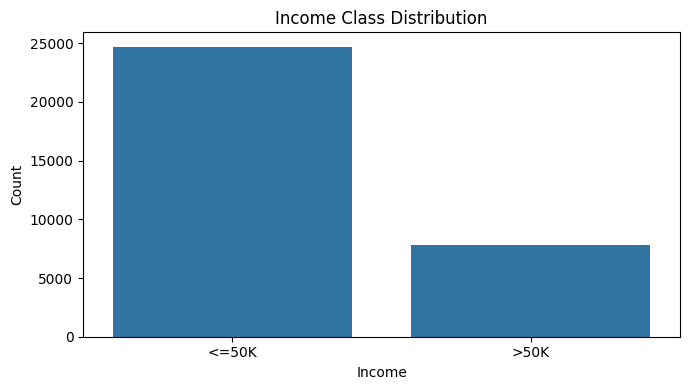

In [6]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=TARGET)
plt.title("Income Class Distribution")
plt.xlabel("Income")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

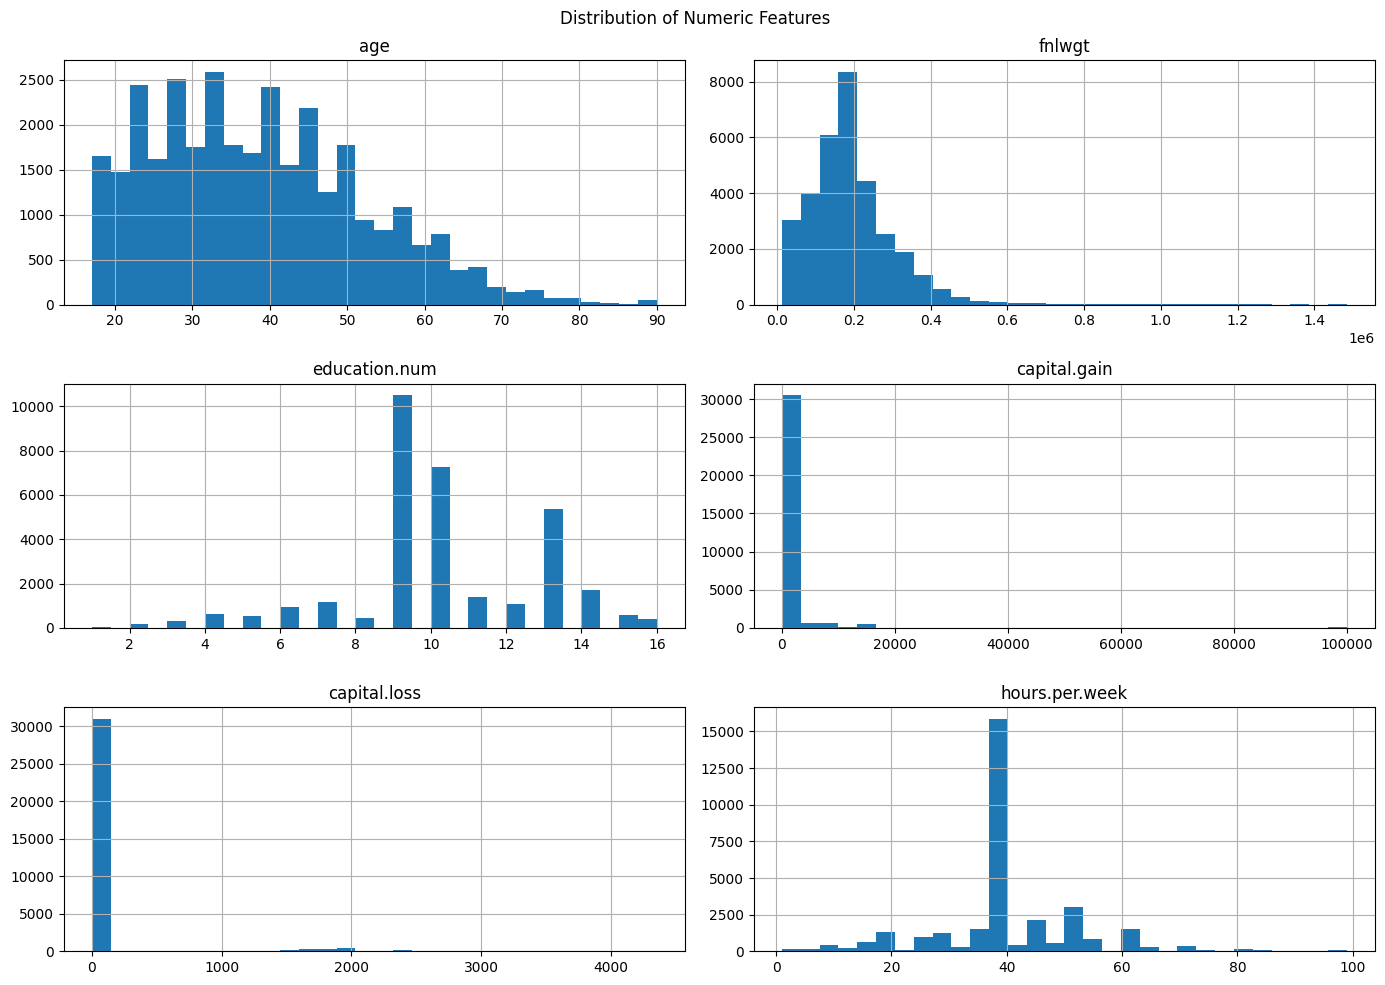

In [7]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

df[num_cols].hist(figsize=(14, 10), bins=30)
plt.suptitle("Distribution of Numeric Features")
plt.tight_layout()
plt.show()

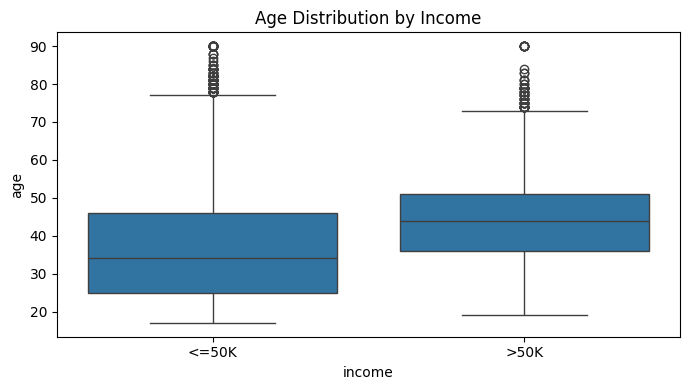

In [8]:
if "age" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=TARGET, y="age")
    plt.title("Age Distribution by Income")
    plt.tight_layout()
    plt.show()

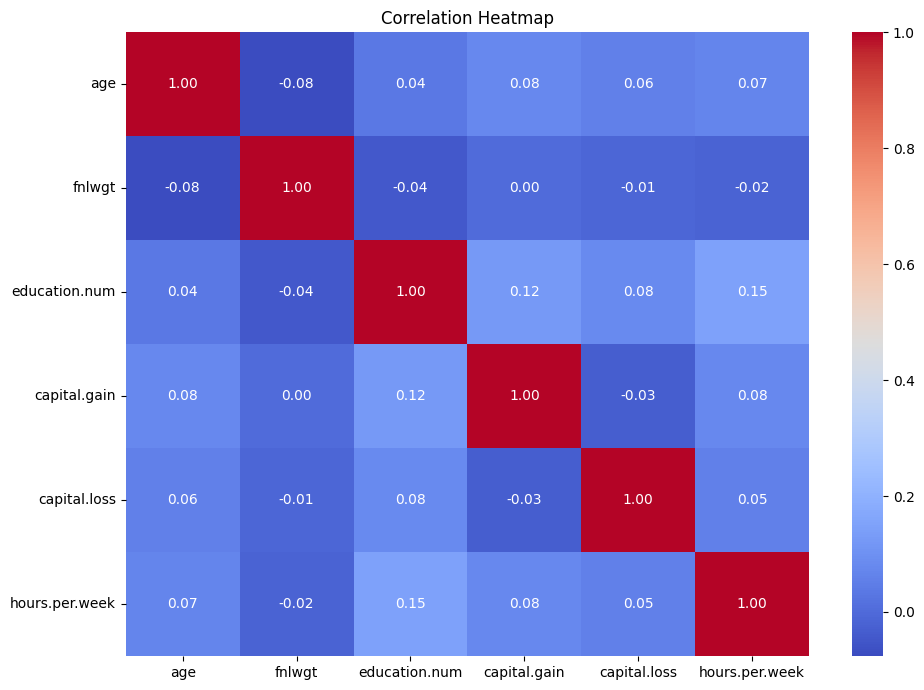

In [9]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

CREATE NEW FEATURES 

In [10]:
# Step 7: Create a New Feature, Encode Data and Select Features

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd

# 1) Create a new feature from existing columns
df["hours_over_40"] = (df["hours.per.week"] - 40).clip(lower=0)

print("New feature created: hours_over_40")
display(df[["hours.per.week", "hours_over_40"]].head())

# 2) Separate X (inputs) and y (target)
TARGET = "income"

X = df.drop(columns=[TARGET])

le_y = LabelEncoder()
y = le_y.fit_transform(df[TARGET].astype(str).str.strip())

print("Classes:", list(le_y.classes_))
# 0 = <=50K, 1 = >50K (if these are the two sorted class labels)

# 3) One-hot encoding: convert text columns into 0/1 columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded dataset shape:", X.shape)
display(X.head())

# 4) Feature selection using SelectKBest
k = min(15, X.shape[1])

selector = SelectKBest(score_func=f_classif, k=k)
selector.fit(X, y)

scores = pd.Series(
    selector.scores_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 20 feature scores:")
display(scores.head(20))

# Keep the selected features
selected_features = scores.head(k).index.tolist()
X = X[selected_features]

feature_names = list(X.columns)

print("\nSelected features:")
print(feature_names)

print("\nFinal feature shape:", X.shape)

New feature created: hours_over_40


,hours.per.week,hours_over_40
0,40,0
1,18,0
2,40,0
3,40,0
4,40,0


Classes: ['<=50K', '>50K']
Encoded dataset shape: (32537, 98)


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,hours_over_40,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_Portugal,native.country_Puerto-Rico,native.country_Scotland,native.country_South,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia
0,90,77053,9,0,4356,40,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
1,82,132870,9,0,4356,18,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,66,186061,10,0,4356,40,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
3,54,140359,4,0,3900,40,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,41,264663,10,0,3900,40,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0



Top 20 feature scores:


marital.status_Married-civ-spouse    8016.009924
education.num                        4120.313326
marital.status_Never-married         3667.499422
age                                  1885.316441
hours.per.week                       1811.533866
relationship_Own-child               1793.852400
capital.gain                         1708.013854
sex_Male                             1591.763761
occupation_Exec-managerial           1575.109853
relationship_Not-in-family           1195.987860
hours_over_40                        1150.503696
education_Bachelors                  1096.139253
education_Masters                    1023.866550
occupation_Other-service              815.065133
education_Prof-school                 799.868289
capital.loss                          754.012116
relationship_Unmarried                678.694460
workclass_Self-emp-inc                645.191842
education_Doctorate                   582.015346
education_HS-grad                     571.115398
dtype: float64


Selected features:
['marital.status_Married-civ-spouse', 'education.num', 'marital.status_Never-married', 'age', 'hours.per.week', 'relationship_Own-child', 'capital.gain', 'sex_Male', 'occupation_Exec-managerial', 'relationship_Not-in-family', 'hours_over_40', 'education_Bachelors', 'education_Masters', 'occupation_Other-service', 'education_Prof-school']

Final feature shape: (32537, 15)


Split data, select features and scale

In [11]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)

# Select up to 15 features using training data only
k = min(15, X_train_raw.shape[1])

selector = SelectKBest(score_func=f_classif, k=k)

X_train_selected = selector.fit_transform(X_train_raw, y_train)
X_test_selected = selector.transform(X_test_raw)

feature_names = X_train_raw.columns[selector.get_support()].tolist()

print("\nSelected features:")
print(feature_names)

# Scale using training data only
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_selected)
X_test = scaler.transform(X_test_selected)

print("\nFinal training shape:", X_train.shape)
print("Final testing shape:", X_test.shape)

Training shape: (26029, 15)
Testing shape: (6508, 15)

Selected features:
['marital.status_Married-civ-spouse', 'education.num', 'marital.status_Never-married', 'age', 'hours.per.week', 'relationship_Own-child', 'capital.gain', 'sex_Male', 'occupation_Exec-managerial', 'relationship_Not-in-family', 'hours_over_40', 'education_Bachelors', 'education_Masters', 'occupation_Other-service', 'education_Prof-school']

Final training shape: (26029, 15)
Final testing shape: (6508, 15)


**Train the baseline Logistic Regression model**

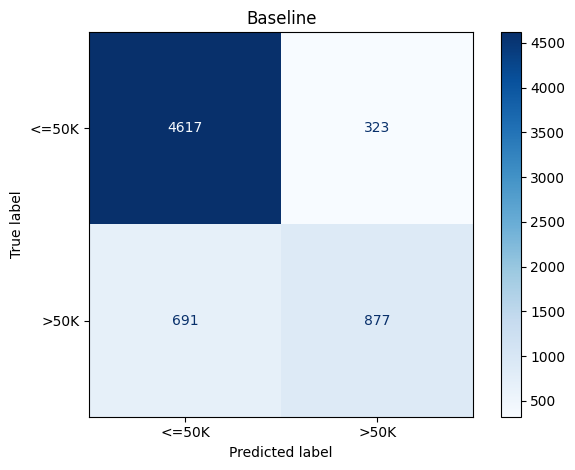


Classification Report:
              precision    recall  f1-score   support

       <=50K       0.87      0.93      0.90      4940
        >50K       0.73      0.56      0.63      1568

    accuracy                           0.84      6508
   macro avg       0.80      0.75      0.77      6508
weighted avg       0.84      0.84      0.84      6508



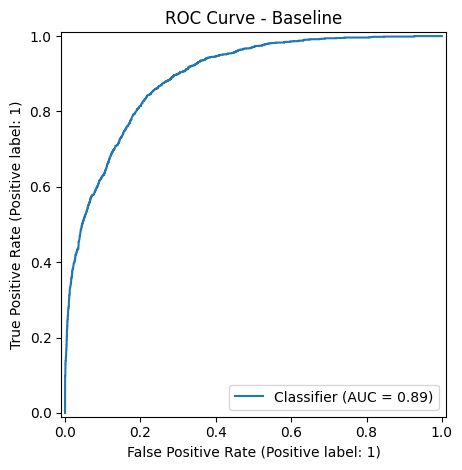

{'Setting': 'Baseline', 'Accuracy': 0.8441917639827904, 'Precision': 0.7308333333333333, 'Recall': 0.5593112244897959, 'F1': 0.6336705202312138, 'Specificity': np.float64(0.9346153846153846), 'AUC': 0.8922574077708006}


In [12]:
results = []

def evaluate(name, model, show=False):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    row = {
        "Setting": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "Specificity": specificity,
        "AUC": roc_auc_score(y_test, probabilities)
    }

    if show:
        ConfusionMatrixDisplay(
            confusion_matrix(y_test, y_pred),
            display_labels=["<=50K", ">50K"]
        ).plot(cmap="Blues")

        plt.title(name)
        plt.tight_layout()
        plt.show()

        print("\nClassification Report:")
        print(classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["<=50K", ">50K"],
            zero_division=0
        ))

        RocCurveDisplay.from_predictions(y_test, probabilities)
        plt.title("ROC Curve - " + name)
        plt.tight_layout()
        plt.show()

    print(row)
    return row

baseline_model = LogisticRegression(max_iter=1000)

results.append(evaluate("Baseline", baseline_model, show=True))

TUNE LOGISTIC REGRESSION

{'Setting': 'class_weight=None', 'Accuracy': 0.8441917639827904, 'Precision': 0.7308333333333333, 'Recall': 0.5593112244897959, 'F1': 0.6336705202312138, 'Specificity': np.float64(0.9346153846153846), 'AUC': 0.8922574077708006}
{'Setting': 'class_weight=balanced', 'Accuracy': 0.7910264290104487, 'Precision': 0.5423797881010595, 'Recall': 0.8488520408163265, 'F1': 0.6618597712580806, 'Specificity': np.float64(0.772672064777328), 'AUC': 0.8924327258737503}

Intercept: [-2.02960815]

Three strongest negative features:
relationship_Own-child     -0.405100
hours_over_40              -0.363408
occupation_Other-service   -0.298350
dtype: float64

Three strongest positive features:
education.num                        0.859435
marital.status_Married-civ-spouse    1.189542
capital.gain                         2.203659
dtype: float64


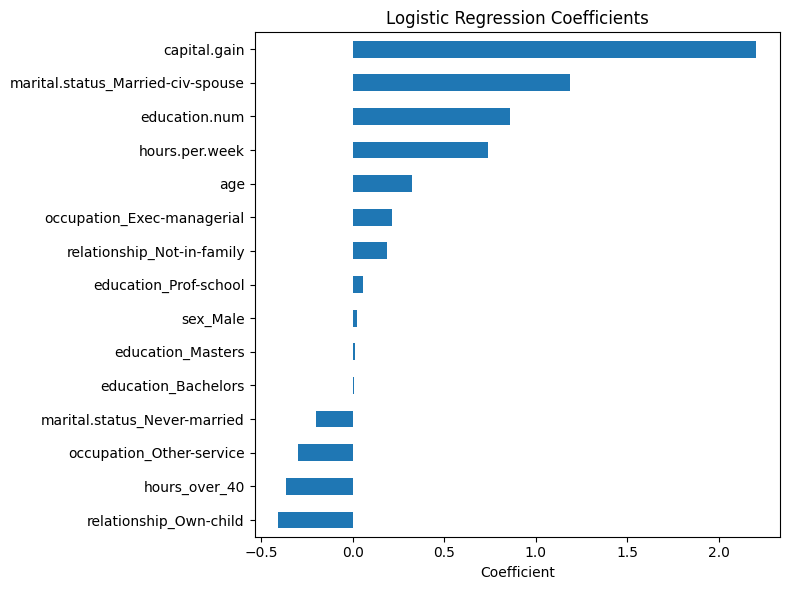


Decision Threshold Comparison:
Threshold: 0.3 | Precision: 0.588 | Recall: 0.774
Threshold: 0.5 | Precision: 0.731 | Recall: 0.559
Threshold: 0.7 | Precision: 0.869 | Recall: 0.358

Model Comparison:


,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,class_weight=None,0.844,0.731,0.559,0.634,0.935,0.892
1,class_weight=balanced,0.791,0.542,0.849,0.662,0.773,0.892


In [13]:


from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

# A) SCALE FEATURES (fit on training data only)
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

# Store results from each setting
results = []

# Evaluation function
def evaluate(name, model, show=False):
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    row = {
        "Setting": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Specificity": specificity,
        "AUC": roc_auc_score(y_test, proba)
    }

    if show:
        ConfusionMatrixDisplay(
            confusion_matrix(y_test, pred),
            display_labels=["<=50K", ">50K"]
        ).plot(cmap="Blues")

        plt.title(name)
        plt.tight_layout()
        plt.show()

        print("\nClassification Report:")
        print(classification_report(
            y_test, pred,
            target_names=["<=50K", ">50K"],
            zero_division=0
        ))

        RocCurveDisplay.from_predictions(y_test, proba)
        plt.title("ROC Curve - " + name)
        plt.tight_layout()
        plt.show()

    print(row)
    return row


# B) COMPARE class_weight=None VS class_weight="balanced"
for cw in [None, "balanced"]:
    model = LogisticRegression(
        max_iter=1000,
        class_weight=cw
    )

    results.append(
        evaluate(f"class_weight={cw}", model)
    )


# C) PRINT INTERCEPT AND COEFFICIENTS
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

print("\nIntercept:", lr.intercept_)

coef = pd.Series(
    lr.coef_[0],
    index=feature_names
).sort_values()

print("\nThree strongest negative features:")
print(coef.head(3))

print("\nThree strongest positive features:")
print(coef.tail(3))

coef.plot(kind="barh", figsize=(8, 6))
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()


# D) COMPARE DECISION THRESHOLDS
proba = lr.predict_proba(X_test)[:, 1]

print("\nDecision Threshold Comparison:")

for t in [0.3, 0.5, 0.7]:
    pred = (proba >= t).astype(int)

    precision = precision_score(
        y_test, pred, zero_division=0
    )
    recall = recall_score(
        y_test, pred, zero_division=0
    )

    print(
        f"Threshold: {t} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f}"
    )


# E) DISPLAY COMPARISON OF MODEL SETTINGS
results_df = pd.DataFrame(results).round(3)

print("\nModel Comparison:")
display(results_df)

COMPARE SETTINGS AND SELECT FINAL MODEL

Model Comparison Table:


,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,class_weight=None,0.844,0.731,0.559,0.634,0.935,0.892
1,class_weight=balanced,0.791,0.542,0.849,0.662,0.773,0.892


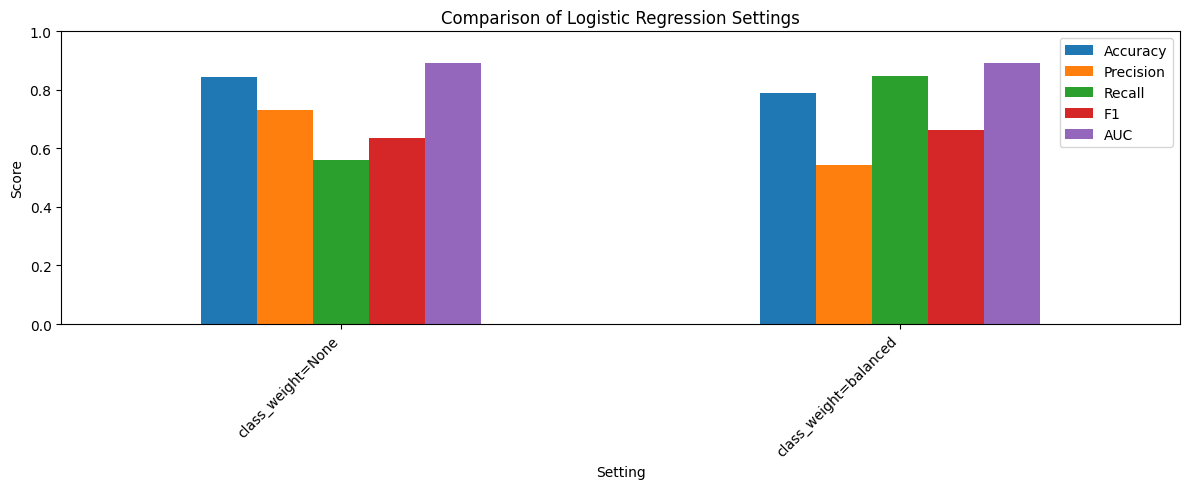

Best setting: class_weight=balanced
Best F1-score: 0.662
Best AUC: 0.892


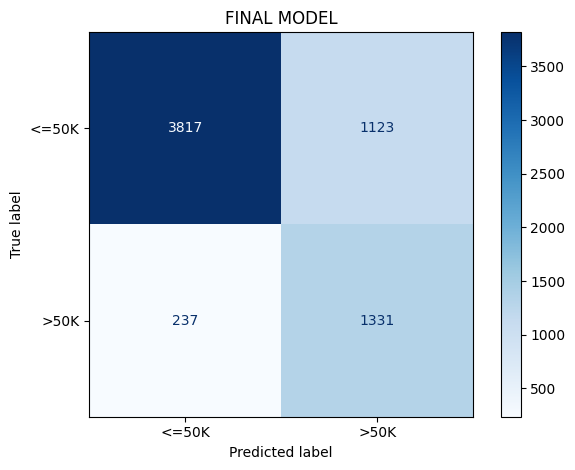


Classification Report:
              precision    recall  f1-score   support

       <=50K       0.94      0.77      0.85      4940
        >50K       0.54      0.85      0.66      1568

    accuracy                           0.79      6508
   macro avg       0.74      0.81      0.76      6508
weighted avg       0.85      0.79      0.80      6508



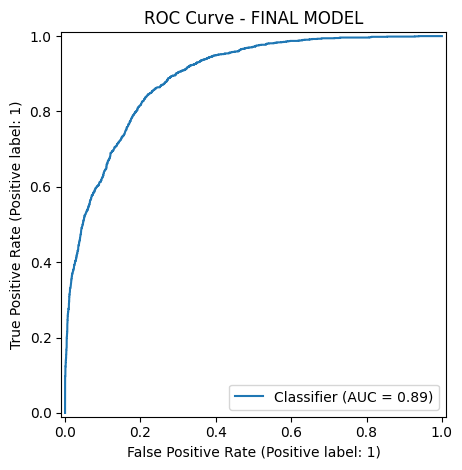

{'Setting': 'FINAL MODEL', 'Accuracy': 0.7910264290104487, 'Precision': 0.5423797881010595, 'Recall': 0.8488520408163265, 'F1': 0.6618597712580806, 'Specificity': np.float64(0.772672064777328), 'AUC': 0.8924327258737503}

Final Model Results:


,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,FINAL MODEL,0.791,0.542,0.849,0.662,0.773,0.892


Model comparison saved to p38_model_comparison.csv


In [14]:


import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# 1. Create a comparison table
res = pd.DataFrame(results).round(3)

print("Model Comparison Table:")
display(res)

# 2. Plot model performance
res.set_index("Setting")[
    ["Accuracy", "Precision", "Recall", "F1", "AUC"]
].plot(kind="bar", figsize=(12, 5))

plt.title("Comparison of Logistic Regression Settings")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3. Select the best setting using F1-score
# Use AUC as a tie-breaker
best = res.sort_values(
    ["F1", "AUC"],
    ascending=False
).iloc[0]

best_setting = best["Setting"]

print("Best setting:", best_setting)
print("Best F1-score:", best["F1"])
print("Best AUC:", best["AUC"])

# 4. Create the final model using the selected setting
if best_setting == "class_weight=balanced":
    final_model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    )
else:
    final_model = LogisticRegression(
        max_iter=1000,
        class_weight=None
    )

# 5. Evaluate the final model
final_results = evaluate(
    "FINAL MODEL",
    final_model,
    show=True
)

print("\nFinal Model Results:")
display(pd.DataFrame([final_results]).round(3))

# 6. Save the comparison table
res.to_csv("p38_model_comparison.csv", index=False)

print("Model comparison saved to p38_model_comparison.csv")

 Use three sample rows from the original encoded features

In [15]:
# Use three sample rows from the original encoded 
new = X.iloc[[0, 1, 2]].copy()

display(new)

# Apply the fitted feature selector and scaler
new_selected = selector.transform(new)
new_scaled = scaler.transform(new_selected)

pred = final_model.predict(new_scaled)
proba = final_model.predict_proba(new_scaled)[:, 1]

prediction_results = pd.DataFrame({
    "Sample": ["Sample 1", "Sample 2", "Sample 3"],
    "Predicted Income": [
        ">50K" if value == 1 else "<=50K"
        for value in pred
    ],
    "Probability of >50K": proba.round(3)
})

display(prediction_results)

,marital.status_Married-civ-spouse,education.num,marital.status_Never-married,age,hours.per.week,relationship_Own-child,capital.gain,sex_Male,occupation_Exec-managerial,relationship_Not-in-family,hours_over_40,education_Bachelors,education_Masters,occupation_Other-service,education_Prof-school
0,0,9,0,90,40,0,0,0,0,1,0,0,0,0,0
1,0,9,0,82,18,0,0,0,1,1,0,0,0,0,0
2,0,10,0,66,40,0,0,0,0,0,0,0,0,0,0


,Sample,Predicted Income,Probability of >50K
0,Sample 1,<=50K,0.357
1,Sample 2,<=50K,0.194
2,Sample 3,<=50K,0.204
